# 04. 모델 튜닝과 오류 분석

**이 노트북에서 하는 일**
1. **GridSearchCV**로 RandomForest · XGBoost · LightGBM의 설정(하이퍼파라미터)을 비교해서 고른다.
2. 고른 모델을 테스트 구간에서 평가하고, 03의 기본 설정 모델과 비교한다.
3. **오류 분석**: 어떤 때 잘 맞히고, 어떤 때 놓치는가? 알림을 실제로 운영한다면 어떻게 되는가?

**교차검증(CV)을 시간 순서로 하는 이유**: 무작위로 섞어 나누면 '미래 데이터로 과거를 맞히는' 누수가 생긴다. `TimeSeriesSplit`은 항상 과거로 학습하고 그 뒤 구간으로 검증하므로 실제 예측 상황과 같다. 5-fold이지만 각 fold의 학습 구간이 점점 길어진다.

**속도를 위한 설계**: 그리드서치는 대여소 200개만 뽑은 부분표본으로 하고, 고른 설정은 전체 학습 데이터로 다시 학습한다. 실행에 이 컴퓨터 기준 10~15분 걸린다(셀 하나씩 진행 상황이 출력된다).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

warnings.filterwarnings("ignore")

# 한글 폰트 (Windows / macOS / Linux 순서로 찾는다)
_have = {f.name for f in fm.fontManager.ttflist}
for _name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if _name in _have:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

# 색: 파랑(주), 주황(비교), 회색(보조)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"

# 경로: notebooks/ 안에서 열든, 저장소 루트에서 열든 동작
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "features.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("저장소 루트:", ROOT)
print("데이터 파일 존재:", DATA.exists())

저장소 루트: /home/claude/repo
데이터 파일 존재: True


In [2]:
import time
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score, confusion_matrix)

df = pd.read_parquet(DATA)
df["gu_code"] = df["gu"].cat.codes
df["op_code"] = df["op"].cat.codes

FEATS = ["stock", "lag1", "lag2", "lag3", "lag6", "lag24", "lag168", "diff1", "diff3", "mean6",
         "hour", "dow", "is_off_day", "temp", "rain", "rain_3h", "humid", "wind", "snow", "temp_diff_3h",
         "lat", "lon", "docks_listed", "gu_code", "op_code",
         "st_mean_stock", "st_std_stock", "st_zero_share", "st_hour_mean"]
VAL_START = pd.Timestamp("2025-12-03")
GAP = pd.Timedelta(hours=3)
SUBSAMPLE_STATIONS = 200   # 그리드서치에 쓸 대여소 수 (줄이면 빨라짐)
SEED = 42

def make_sets(h):
    y = f"y_h{h}"
    d = df[(df.at_risk == 1) & df[y].notna() & (df.split != "gap")]
    tr = d[(d.split == "train") & (d.ts < VAL_START - GAP)]
    va = d[(d.split == "train") & (d.ts >= VAL_START)]
    te = d[d.split == "test"]
    return tr, va, te, y

def best_threshold(y, s):
    P, R, T = precision_recall_curve(y, s)
    F = 2 * P * R / (P + R + 1e-12)
    return T[np.nanargmax(F[:-1])]

def evaluate(name, yv, sv, yt, st):
    thr = best_threshold(yv, sv)
    pred = (st >= thr).astype(int)
    return {"모델": name, "PR-AUC": average_precision_score(yt, st), "ROC-AUC": roc_auc_score(yt, st),
            "Precision": precision_score(yt, pred),
            "Recall": recall_score(yt, pred), "F1": f1_score(yt, pred), "Accuracy": accuracy_score(yt, pred),
            "임계값": thr}

tr, va, te, y = make_sets(1)
print(f"h=1  학습 {len(tr):,} / 검증 {len(va):,} / 테스트 {len(te):,}행")

h=1  학습 3,264,663 / 검증 418,477 / 테스트 1,094,981행


## 1. 그리드서치용 부분표본 만들기

대여소 200개를 무작위로 뽑고, 학습 구간 데이터를 **시간 순으로 정렬**한다(TimeSeriesSplit의 전제 조건).
`gap`은 학습 구간 끝과 검증 구간 시작 사이에 비워 두는 행 수로, 3시간 치(대여소 수 x 3)를 둔다.

In [3]:
rng = np.random.default_rng(SEED)
stations = tr["station_id"].cat.remove_unused_categories().cat.categories
pick = set(rng.choice(stations, SUBSAMPLE_STATIONS, replace=False))
sub = tr[tr.station_id.isin(pick)].sort_values("ts")
Xg, yg = sub[FEATS], sub[y]
cv = TimeSeriesSplit(n_splits=5, gap=SUBSAMPLE_STATIONS * 3)
print(f"그리드서치 데이터: {len(sub):,}행, 사건 비율 {yg.mean():.2%}")
for i, (a, b) in enumerate(cv.split(Xg), 1):
    print(f"fold {i}: 학습 {len(a):>7,}행 ({sub.ts.iloc[a[0]]:%m/%d}~{sub.ts.iloc[a[-1]]:%m/%d}) -> 검증 {len(b):,}행 ({sub.ts.iloc[b[0]]:%m/%d}~{sub.ts.iloc[b[-1]]:%m/%d})")

그리드서치 데이터: 235,588행, 사건 비율 3.58%
fold 1: 학습  38,668행 (10/01~10/11) -> 검증 39,264행 (10/11~10/21)
fold 2: 학습  77,932행 (10/01~10/21) -> 검증 39,264행 (10/21~11/01)
fold 3: 학습 117,196행 (10/01~11/01) -> 검증 39,264행 (11/01~11/12)
fold 4: 학습 156,460행 (10/01~11/12) -> 검증 39,264행 (11/12~11/22)
fold 5: 학습 195,724행 (10/01~11/22) -> 검증 39,264행 (11/22~12/02)


## 2. GridSearchCV

점수는 **PR-AUC(`average_precision`)**로 매긴다. 불균형 문제라 정확도로 고르면 '전부 부족하지 않음'을 고르게 된다.

| 모델 | 비교하는 설정 |
|---|---|
| RandomForest | 나무 깊이 `max_depth` 10/16, 잎 최소 행 `min_samples_leaf` 20/100 |
| LightGBM | 잎 개수 `num_leaves` 31/63/127, `min_child_samples` 50/200, 나무 수 150/300 |
| XGBoost | 나무 깊이 `max_depth` 4/6/8, 나무 수 150/300 |

나무가 깊거나 많을수록 학습 데이터에 과하게 맞춰질(과적합) 수 있어서, 검증 점수로 적당한 선을 고른다.

In [4]:
def run_grid(name, est, grid, fill=False):
    t = time.time()
    gs = GridSearchCV(est, grid, scoring="average_precision", cv=cv, n_jobs=1, refit=False, verbose=0)
    gs.fit(Xg.fillna(-1) if fill else Xg, yg)   # RandomForest는 빈칸(NaN)을 -1로 채워서 사용
    r = pd.DataFrame(gs.cv_results_)
    r["모델"] = name
    print(f"{name}: {len(r)}개 조합 x 5 fold, {time.time()-t:.0f}초 | 최고 평균 PR-AUC {r.mean_test_score.max():.4f}")
    return gs, r

searches = {}
searches["RandomForest"] = run_grid(
    "RandomForest",
    RandomForestClassifier(n_estimators=80, n_jobs=-1, random_state=SEED),
    {"max_depth": [10, 16], "min_samples_leaf": [20, 100]}, fill=True)

RandomForest: 4개 조합 x 5 fold, 112초 | 최고 평균 PR-AUC 0.3517


In [5]:
searches["LightGBM"] = run_grid(
    "LightGBM",
    lgb.LGBMClassifier(learning_rate=0.1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       n_jobs=-1, verbose=-1, random_state=SEED),
    {"num_leaves": [31, 63, 127], "min_child_samples": [50, 200], "n_estimators": [150, 300]})

LightGBM: 12개 조합 x 5 fold, 144초 | 최고 평균 PR-AUC 0.3712


In [6]:
searches["XGBoost"] = run_grid(
    "XGBoost",
    xgb.XGBClassifier(learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                      n_jobs=-1, eval_metric="logloss", random_state=SEED),
    {"max_depth": [4, 6, 8], "n_estimators": [150, 300]})

XGBoost: 6개 조합 x 5 fold, 59초 | 최고 평균 PR-AUC 0.3728


In [7]:
# 모델별 최고 조합과 CV 점수 (평균 +- 표준편차는 5개 fold 사이의 흔들림)
rows, best_params = [], {}
for name, (gs, r) in searches.items():
    b = r.sort_values("mean_test_score", ascending=False).iloc[0]
    best_params[name] = b["params"]
    rows.append({"모델": name, "최고 조합": b["params"], "CV PR-AUC 평균": round(b["mean_test_score"], 4),
                 "표준편차": round(b["std_test_score"], 4)})
cv_summary = pd.DataFrame(rows)
cv_summary.to_csv(ROOT / "reports" / "tuning_cv_summary.csv", index=False, encoding="utf-8-sig")
all_cv = pd.concat([r.assign(params=r.params.astype(str))[["모델", "params", "mean_test_score", "std_test_score", "rank_test_score"]]
                    for _, (_, r) in searches.items()])
all_cv.to_csv(ROOT / "reports" / "tuning_cv_all.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 120)
cv_summary

,모델,최고 조합,CV PR-AUC 평균,표준편차
0,RandomForest,"{'max_depth': 16, 'min_samples_leaf': 20}",0.3517,0.0194
1,LightGBM,"{'min_child_samples': 200, 'n_estimators': 150, 'num_leaves': 31}",0.3712,0.0344
2,XGBoost,"{'max_depth': 4, 'n_estimators': 300}",0.3728,0.0283


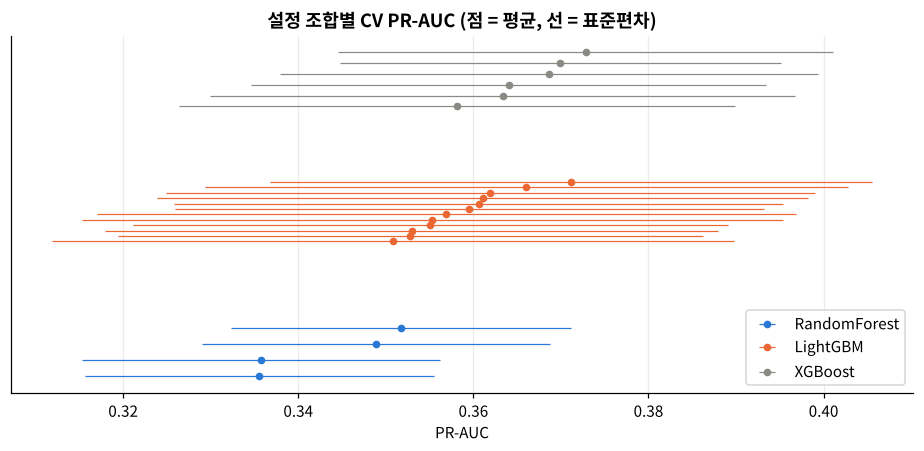

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, (name, (gs, r)) in enumerate(searches.items()):
    s = r.sort_values("mean_test_score")
    ax.errorbar(s.mean_test_score, [k + 0.12 * (i - len(s) / 2) / len(s) * 4 for i in range(len(s))], xerr=s.std_test_score,
                fmt="o", ms=4, lw=0.8, color=[BLUE, ORANGE, GRAY][k], label=name)
ax.set_yticks([]); ax.legend(loc="lower right")
ax.set(title="설정 조합별 CV PR-AUC (점 = 평균, 선 = 표준편차)", xlabel="PR-AUC")
plt.tight_layout(); plt.savefig(FIG / "tune_01_cv_scores.png", bbox_inches="tight"); plt.show()

## 3. 고른 설정으로 전체 학습 데이터에 다시 학습 → 테스트 평가

03과 똑같은 방식(학습 / 검증으로 임계값 선택 / 테스트)이라 **숫자를 직접 비교**할 수 있다.

In [9]:
yv, yt = va[y].values, te[y].values
Xtr, Xva, Xte = tr[FEATS], va[FEATS], te[FEATS]
final, res = {}, []

t = time.time()
rf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED, **best_params["RandomForest"])
smp = tr.sample(600_000, random_state=SEED)   # 속도를 위해 60만 행만 사용
rf.fit(smp[FEATS].fillna(-1), smp[y])
final["RandomForest"] = rf
f = lambda m, X: m.predict_proba(X.fillna(-1))[:, 1]
res.append(evaluate("RandomForest (튜닝)", yv, f(rf, Xva), yt, f(rf, Xte)))
print(f"RandomForest {time.time()-t:.0f}초")

t = time.time()
lg = lgb.LGBMClassifier(learning_rate=0.1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        n_jobs=-1, verbose=-1, random_state=SEED, **best_params["LightGBM"]).fit(Xtr, tr[y])
final["LightGBM"] = lg
res.append(evaluate("LightGBM (튜닝)", yv, lg.predict_proba(Xva)[:, 1], yt, lg.predict_proba(Xte)[:, 1]))
print(f"LightGBM {time.time()-t:.0f}초")

t = time.time()
xg = xgb.XGBClassifier(learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                       n_jobs=-1, eval_metric="logloss", random_state=SEED, **best_params["XGBoost"]).fit(Xtr, tr[y])
final["XGBoost"] = xg
res.append(evaluate("XGBoost (튜닝)", yv, xg.predict_proba(Xva)[:, 1], yt, xg.predict_proba(Xte)[:, 1]))
print(f"XGBoost {time.time()-t:.0f}초")

prev = pd.read_csv(ROOT / "reports" / "model_comparison_h1.csv", index_col=0)
base = prev.loc[["규칙 B: 재고가 낮을수록", "LightGBM"]].reset_index().rename(columns={"모델": "모델"})
base["모델"] = ["규칙 B (기준선)", "LightGBM (03, 기본 설정)"]
res_tab = pd.concat([base, pd.DataFrame(res)], ignore_index=True).set_index("모델").drop(columns=["임계값"], errors="ignore").round(4)
res_tab.to_csv(ROOT / "reports" / "tuning_test_results_h1.csv", encoding="utf-8-sig")
res_tab

RandomForest 102초


LightGBM 31초


XGBoost 58초


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
모델,,,,,,
규칙 B (기준선),0.2069,0.9311,0.2461,0.6217,0.3526,0.9407
"LightGBM (03, 기본 설정)",0.3626,0.9588,0.3348,0.5444,0.4146,0.9601
RandomForest (튜닝),0.3217,0.9530,0.2957,0.5843,0.3927,0.9531
LightGBM (튜닝),0.3619,0.9583,0.3206,0.5803,0.4130,0.9572
XGBoost (튜닝),0.3555,0.9574,0.3203,0.5574,0.4068,0.9578


In [10]:
# 가장 좋은 모델 선택 (테스트가 아니라 CV 점수 기준으로 골라야 공정하다 -> 둘 다 보여준다)
best_cv = cv_summary.sort_values("CV PR-AUC 평균", ascending=False).iloc[0]["모델"]
best_test = res_tab.drop(index=["규칙 B (기준선)", "LightGBM (03, 기본 설정)"])["PR-AUC"].idxmax()
print("CV 기준 1위:", best_cv, "| 테스트 PR-AUC 기준 1위:", best_test)
BEST = best_cv   # 선택은 CV 기준을 따른다 (테스트 점수로 고르면 테스트에 과적합됨)
model = final[BEST]
pred_fn = (lambda X: model.predict_proba(X.fillna(-1))[:, 1]) if BEST == "RandomForest" else (lambda X: model.predict_proba(X)[:, 1])
print("최종 선택 모델:", BEST, best_params[BEST])

CV 기준 1위: XGBoost | 테스트 PR-AUC 기준 1위: LightGBM (튜닝)
최종 선택 모델: XGBoost {'max_depth': 4, 'n_estimators': 300}


## 4. Feature Importance (최종 모델)

변수가 예측에 얼마나 기여했는지 본다. 1위와 2위 변수는 보고서에 반드시 쓴다.

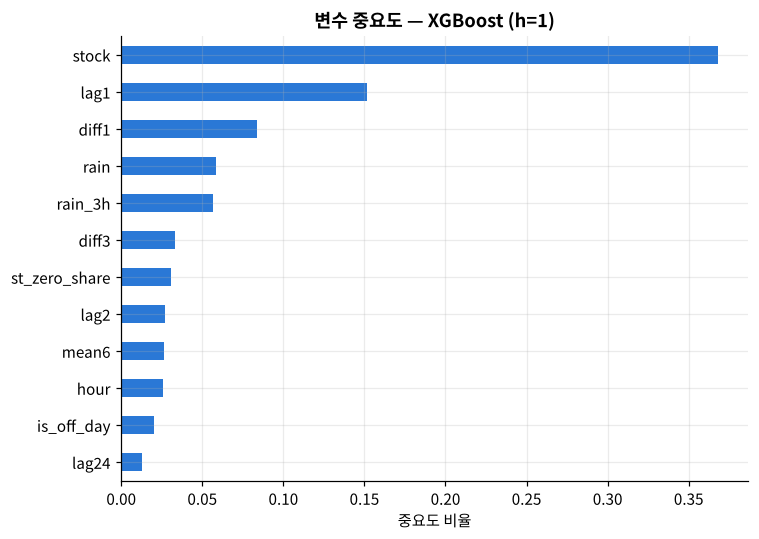

1위 stock (36.8%), 2위 lag1 (15.2%)


,중요도
stock,0.3682
lag1,0.1519
diff1,0.0837
rain,0.0586
rain_3h,0.0566
diff3,0.0331
st_zero_share,0.0305
lag2,0.0268
mean6,0.0265
hour,0.0258


In [11]:
if BEST == "LightGBM":
    imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATS)
else:
    imp = pd.Series(model.feature_importances_, index=FEATS)
imp = (imp / imp.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
imp.head(12)[::-1].plot.barh(ax=ax, color=BLUE)
ax.set(title=f"변수 중요도 — {BEST} (h=1)", xlabel="중요도 비율")
plt.tight_layout(); plt.savefig(FIG / "tune_02_feature_importance.png", bbox_inches="tight"); plt.show()
print(f"1위 {imp.index[0]} ({imp.iloc[0]:.1%}), 2위 {imp.index[1]} ({imp.iloc[1]:.1%})")
imp.head(10).round(4).to_frame("중요도")

## 5. 오류 분석 — 어디서 맞히고 어디서 놓치는가

임계값은 검증 구간에서 F1이 최대인 값을 쓴다. 용어:
- **TP**: 부족이 생길 거라 알렸고, 실제로 생김 / **FP**: 알렸지만 안 생김(오탐) / **FN**: 알리지 못했는데 생김(놓침) / **TN**: 알리지 않았고 안 생김

In [12]:
thr = best_threshold(yv, pred_fn(Xva))
te = te.assign(p=pred_fn(Xte), pred=lambda d: (d.p >= thr).astype(int))
tn, fp, fn, tp = confusion_matrix(te[y], te.pred).ravel()
print(f"임계값 {thr:.3f}")
print(pd.DataFrame({"실제 부족 발생": [tp, fn], "실제 부족 없음": [fp, tn]}, index=["알림 보냄", "알림 안 보냄"]))
print(f"\nPrecision {tp/(tp+fp):.3f} (알림 중 맞은 비율) / Recall {tp/(tp+fn):.3f} (실제 사건 중 잡은 비율)")

임계값 0.207
         실제 부족 발생  실제 부족 없음
알림 보냄       15848     33631
알림 안 보냄     12585   1032917

Precision 0.320 (알림 중 맞은 비율) / Recall 0.557 (실제 사건 중 잡은 비율)


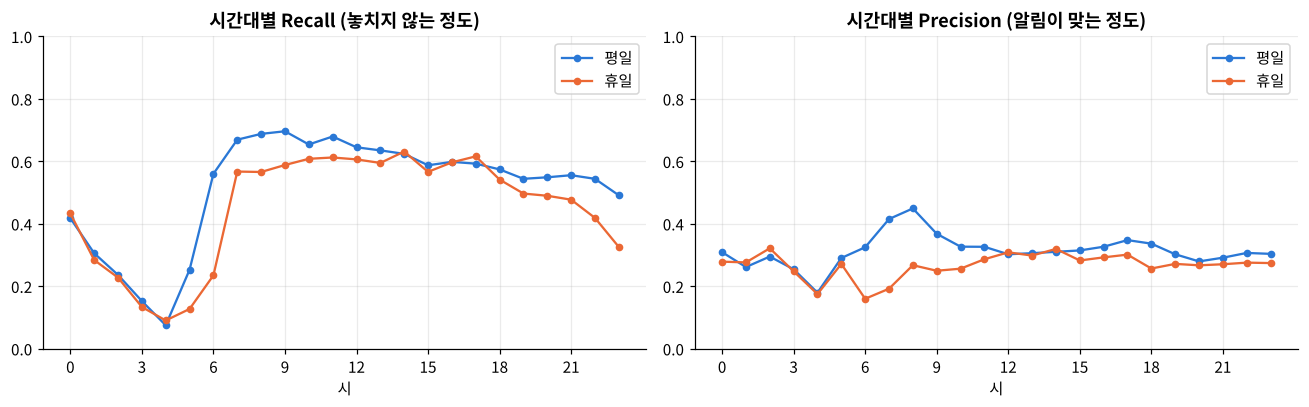

,사건 수,Recall,Precision
hour,,,
7,1695.0,0.669,0.415
8,2247.0,0.688,0.449
9,1332.0,0.696,0.368
17,1219.0,0.592,0.347
18,1232.0,0.574,0.336
19,903.0,0.544,0.302


In [13]:
# (a) 시간대별 Recall / Precision — 출퇴근에는 잘 잡나?
te["day_type"] = np.where(te.is_off_day == 1, "휴일", "평일")
g = te.groupby(["day_type", "hour"]).apply(lambda d: pd.Series({
    "사건 수": d[y].sum(),
    "Recall": (d.pred[d[y] == 1]).mean() if d[y].sum() else np.nan,
    "Precision": (d[y][d.pred == 1]).mean() if d.pred.sum() else np.nan}))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for dt_, c in [("평일", BLUE), ("휴일", ORANGE)]:
    s = g.loc[dt_]
    ax[0].plot(s.index, s["Recall"], marker="o", ms=4, color=c, label=dt_)
    ax[1].plot(s.index, s["Precision"], marker="o", ms=4, color=c, label=dt_)
ax[0].set(title="시간대별 Recall (놓치지 않는 정도)", xlabel="시", ylim=(0, 1)); ax[1].set(title="시간대별 Precision (알림이 맞는 정도)", xlabel="시", ylim=(0, 1))
for a in ax: a.legend(); a.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.savefig(FIG / "tune_03_error_by_hour.png", bbox_inches="tight"); plt.show()
g.loc["평일"].loc[[7, 8, 9, 17, 18, 19]].round(3)

In [14]:
# (b) 현재 재고 수준별 — 재고가 많은데 갑자기 줄어드는 경우도 잡나?
te["stock_grp"] = pd.cut(te.stock, [2, 3, 5, 9, 19, 1000], labels=["3", "4~5", "6~9", "10~19", "20+"])
s = te.groupby("stock_grp", observed=True).apply(lambda d: pd.Series({
    "행 수": len(d), "사건 수": int(d[y].sum()), "사건 비율": d[y].mean(),
    "Recall": d.pred[d[y] == 1].mean() if d[y].sum() else np.nan}))
s["전체 사건 중 비중"] = s["사건 수"] / s["사건 수"].sum()
print(s.round(3))

# (c) 대여소 특성별 — 자주 비는 대여소는 잘 잡나?
te["st_grp"] = pd.qcut(te.st_zero_share, 4, labels=["거의 안 빔", "가끔 빔", "자주 빔", "매우 자주 빔"], duplicates="drop")
s2 = te.groupby("st_grp", observed=True).apply(lambda d: pd.Series({
    "사건 비율": d[y].mean(), "Recall": d.pred[d[y] == 1].mean(), "Precision": d[y][d.pred == 1].mean()}))
print(); print(s2.round(3))

                행 수     사건 수  사건 비율  Recall  전체 사건 중 비중
stock_grp                                              
3           71821.0  17676.0  0.246   0.749       0.622
4~5        128994.0   8355.0  0.065   0.251       0.294
6~9        215433.0   1873.0  0.009   0.208       0.066
10~19      374189.0    483.0  0.001   0.259       0.017
20+        304544.0     46.0  0.000   0.065       0.002

         사건 비율  Recall  Precision
st_grp                           
거의 안 빔   0.007   0.256      0.301
가끔 빔     0.018   0.434      0.331
자주 빔     0.031   0.543      0.326
매우 자주 빔  0.048   0.653      0.316


## 6. 알림을 실제로 운영한다면 — 임계값별 시나리오

임계값을 낮추면 더 많이 잡지만 오탐도 늘고, 높이면 정확하지만 놓친다. **운영자가 하루에 보낼 수 있는 알림 수**가 정해져 있다면 거기에 맞춰 고르면 된다.
(테스트 21일, 대여소 약 2,700개 기준)

In [15]:
days = te.ts.dt.normalize().nunique()
rows = []
for q in [0.15, 0.2, 0.3, 0.4, 0.5, 0.6]:
    a = te.p >= q
    tp_ = int((a & (te[y] == 1)).sum())
    rows.append({"임계값": q, "하루 알림 수": round(a.sum() / days), "Precision": round(tp_ / max(a.sum(), 1), 3),
                 "Recall": round(tp_ / te[y].sum(), 3), "하루 잡는 사건 수": round(tp_ / days),
                 "하루 전체 사건 수": round(te[y].sum() / days)})
scen = pd.DataFrame(rows)
scen.to_csv(ROOT / "reports" / "alert_scenarios_h1.csv", index=False, encoding="utf-8-sig")
scen

,임계값,하루 알림 수,Precision,Recall,하루 잡는 사건 수,하루 전체 사건 수
0,0.15,3438,0.277,0.703,952,1354
1,0.20,2484,0.315,0.577,782,1354
2,0.30,1078,0.400,0.319,431,1354
3,0.40,386,0.499,0.142,193,1354
4,0.50,135,0.598,0.060,81,1354
5,0.60,50,0.713,0.026,36,1354


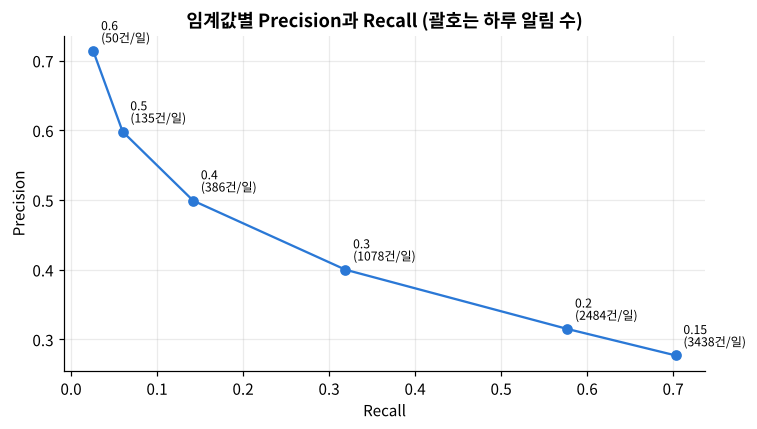

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scen["Recall"], scen["Precision"], marker="o", color=BLUE)
for _, r in scen.iterrows():
    ax.annotate(f'{r["임계값"]}\n({int(r["하루 알림 수"])}건/일)', (r["Recall"], r["Precision"]), textcoords="offset points", xytext=(5, 6), fontsize=8)
ax.set(title="임계값별 Precision과 Recall (괄호는 하루 알림 수)", xlabel="Recall", ylabel="Precision")
plt.tight_layout(); plt.savefig(FIG / "tune_04_alert_scenarios.png", bbox_inches="tight"); plt.show()

In [17]:
# 2, 3시간 뒤 예측 (선택한 설정으로) — 미리 알릴수록 대응 시간이 늘어나는 대신 정확도는?
rows = []
for h in (1, 2, 3):
    tr_h, va_h, te_h, y_h = make_sets(h)
    if BEST == "LightGBM":
        m = lgb.LGBMClassifier(learning_rate=0.1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1,
                               verbose=-1, random_state=SEED, **best_params["LightGBM"]).fit(tr_h[FEATS], tr_h[y_h])
        pf = lambda X: m.predict_proba(X[FEATS])[:, 1]
    elif BEST == "XGBoost":
        m = xgb.XGBClassifier(learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                              eval_metric="logloss", random_state=SEED, **best_params["XGBoost"]).fit(tr_h[FEATS], tr_h[y_h])
        pf = lambda X: m.predict_proba(X[FEATS])[:, 1]
    else:
        sm = tr_h.sample(600_000, random_state=SEED)
        m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED, **best_params["RandomForest"]).fit(sm[FEATS].fillna(-1), sm[y_h])
        pf = lambda X: m.predict_proba(X[FEATS].fillna(-1))[:, 1]
    r = evaluate(f"{BEST} (튜닝)", va_h[y_h].values, pf(va_h), te_h[y_h].values, pf(te_h))
    rows.append({"시점": f"{h}시간 뒤", "사건 비율": te_h[y_h].mean(), **r})
res_h = pd.DataFrame(rows).drop(columns=["임계값"]).round(4)
res_h.to_csv(ROOT / "reports" / "tuning_by_horizon.csv", index=False, encoding="utf-8-sig")
res_h

,시점,사건 비율,모델,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
0,1시간 뒤,0.0260,XGBoost (튜닝),0.3555,0.9574,0.3203,0.5574,0.4068,0.9578
1,2시간 뒤,0.0398,XGBoost (튜닝),0.4016,0.9443,0.3679,0.5505,0.4410,0.9444
2,3시간 뒤,0.0506,XGBoost (튜닝),0.4263,0.9339,0.3872,0.5628,0.4588,0.9328


## 7. 정리

**1. 튜닝 결과: 설정을 바꿔도 성능은 거의 달라지지 않았다**

| 모델 (튜닝) | CV PR-AUC (평균 ± 표준편차) | 테스트 PR-AUC |
|---|---|---|
| RandomForest | 0.352 ± 0.019 | 0.322 |
| LightGBM | 0.371 ± 0.034 | 0.362 |
| XGBoost | **0.373 ± 0.028** | 0.356 |

- LightGBM과 XGBoost의 CV 차이(0.002)는 fold 사이 흔들림(0.03)보다 훨씬 작아 **사실상 동률**이다. 03의 기본 설정 LightGBM(테스트 0.363)도 튜닝 결과와 같은 수준이다.
- 선택 규칙은 '**CV 점수 1위**'로 정했고, 그에 따라 최종 모델은 **XGBoost(max_depth 4, n_estimators 300)**다. 테스트 점수로 고르면 테스트에 과적합되기 때문이다. RandomForest만 일관되게 한 단계 낮다.
- 의미: 성능의 한계는 모델 설정이 아니라 **입력 정보**에 있다. 이 데이터로는 PR-AUC 0.36 안팎이 천장에 가깝다.

**2. 최종 모델 성능 (XGBoost, 테스트)**

| 시점 | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| 1시간 뒤 | 0.356 | 0.320 | 0.557 | 0.407 |
| 2시간 뒤 | 0.402 | 0.368 | 0.551 | 0.441 |
| 3시간 뒤 | 0.426 | 0.387 | 0.563 | 0.459 |

(시점이 멀수록 사건 비율이 커져서 PR-AUC가 오르는 효과가 섞여 있다.)

**3. 변수 중요도**: 1위 `stock`(현재 재고, 36.8%), 2위 `lag1`(1시간 전 재고, 15.2%). 03의 LightGBM에서도 두 변수가 1·2위였다. 그 아래 순위(비, 시간대 등)는 모델마다 달라서 해석을 단정하지 않는다.

**4. 오류 분석 (h=1, 임계값 0.207)**
- 알림 49,479건 중 15,848건이 맞고(Precision 0.32), 실제 사건 28,433건 중 15,848건을 잡았다(Recall 0.56).
- **현재 재고가 3대일 때는 잘 잡는다**(사건의 62%가 여기서 발생, Recall 0.75). 재고가 4~5대면 Recall이 0.25로 떨어지고, 6대 이상이면 0.2 안팎이다. 이런 '재고가 많다가 한 시간 만에 급감하는' 사건이 전체의 약 8%인데 거의 못 잡는다. 모델은 사실상 '재고가 이미 얼마 안 남은 곳이 곧 바닥나는가'를 맞히는 셈이다.
- **평일 출근(7~9시)에 가장 잘 맞는다**(Recall 0.67~0.70, Precision 0.37~0.45). 저녁(17~19시)은 한 단계 낮다(Recall 0.54~0.59, Precision 0.30~0.35).
- **자주 비는 대여소일수록 잘 잡는다**(Recall: 거의 안 빔 0.26 → 매우 자주 빔 0.65).

**5. 운영 시나리오와 실행 제언**
- 임계값 0.3이면 하루 약 1,078건을 알리고 그중 40%가 맞으며, 하루 사건 1,354건 중 431건(32%)을 잡는다. 0.2면 하루 2,484건, 정확도 31.5%로 58%를 잡는다. **운영자가 처리할 수 있는 알림 수에 맞춰 임계값을 고르면 된다.**
- 출근 시간대(평일 7~9시)의 알림이 가장 믿을 만하므로 **출근 전 선제 재배치**에 먼저 쓰는 것이 합리적이다. 상시 비어 있는 대여소 67곳은 모델 이전에 **운영 점검 대상**이다.

**6. 한계**
- Precision이 0.3대라 알림 3건 중 2건은 헛걸음이다. 재고가 충분하다가 급감하는 사건은 거의 못 잡는다.
- 한 계절(2025년 4분기) 자료이고, 테스트 구간의 사건 비율(2.6%)이 학습(3.65%)보다 낮은 분포 변화가 있다.
- 노트북을 다시 실행하면 LightGBM과 XGBoost의 CV 순위가 바뀔 수 있다(차이가 오차 범위 안이므로). 보고서에는 실제로 실행한 값을 적는다.